# Ejercicio Ridge, Lasso y ElasticNet
Para este ejercicio vas a trabajar con datos de ventas de una empresa que fabrica muebles en España. Esta empresa es una Pyme que demanda conocer de antemano qué ingresos va a tener cada mes, ya que necesita pedir un anticipio a su entidad financiera de cara a poder abastecerse de materia prima al comenzar el mes. Como desconoce cuánto tiene que pedir, tira al alza y acaba pagando muchos intereses. El objetivo es reducir estos gastos.

En las bases de datos de la empresa constan todos los gastos en publicidad y ventas, para cada uno de los meses desde su fundación (hace más de 15 años).

Dado que los presupuestos de marketing se cierran al principio de cada mes, la empresa necesita un modelo predictivo que le anticipe las ventas que conseguirá a final de mes en función de los gastos que realizará en marketing.

Para ello tendrás que utilizar tanto modelos de regresión normales, como regularizados.

1. Carga los datos y realiza un pequeño análisis exploratorio. Mira a ver cómo se relaciona las ventas con el resto de variables.
2. Crea varios modelos y modifica los hiperparámetros necesarios para mejorar el performance del modelo.
3. Interpreta los resultados. Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). ¿Cuánto cambian las ventas si aumentamos la inversión en radio un punto más? ¿Y si aumentamos la inversión en TV o periódicos?

## Import libraries 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

## Exploratory Data Analysis 

In [2]:
# Lectura datos, relación variables, mapas de correlación...
df = pd.read_csv('data/Advertising.csv')
df.head()

,Unnamed: 0,TV,radio,newpaper,sales
0,0,230.1,37.8,6s9.2,22100.0
1,1,44.5,39.3,45.1,10400.0
2,2,17.2,45.9,69.3,9300.0
3,3,151.5,41.3,58.5,18500.0
4,4,180.8,10.8,58.4,12900.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   radio       200 non-null    float64
 3   newpaper    200 non-null    object 
 4   sales       200 non-null    float64
dtypes: float64(3), int64(1), object(1)
memory usage: 7.9+ KB


In [4]:
df.describe()

,Unnamed: 0,TV,radio,sales
count,200.000000,200.000000,200.000000,200.000000
mean,99.500000,147.042500,23.264000,14022.500000
std,57.879185,85.854236,14.846809,5217.456566
min,0.000000,0.700000,0.000000,1600.000000
25%,49.750000,74.375000,9.975000,10375.000000
50%,99.500000,149.750000,22.900000,12900.000000
75%,149.250000,218.825000,36.525000,17400.000000
max,199.000000,296.400000,49.600000,27000.000000


In [5]:
df = df.drop(columns = 'Unnamed: 0', axis=1)
df

,TV,radio,newpaper,sales
0,230.1,37.8,6s9.2,22100.0
1,44.5,39.3,45.1,10400.0
2,17.2,45.9,69.3,9300.0
3,151.5,41.3,58.5,18500.0
4,180.8,10.8,58.4,12900.0
...,...,...,...,...
195,38.2,3.7,13.8,7600.0
196,94.2,4.9,8.1,9700.0
197,177.0,9.3,6.4,12800.0
198,283.6,42.0,66.2,25500.0


In [6]:
df = df[pd.to_numeric(df['newpaper'], errors='coerce').notnull()]

In [7]:
df.loc[:,'newpaper'] = pd.to_numeric(df['newpaper'])

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 199 entries, 1 to 199
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   TV        199 non-null    float64
 1   radio     199 non-null    float64
 2   newpaper  199 non-null    object 
 3   sales     199 non-null    float64
dtypes: float64(3), object(1)
memory usage: 7.8+ KB


In [9]:
df.describe()

,TV,radio,sales
count,199.000000,199.000000,199.000000
mean,146.625126,23.190955,13981.909548
std,85.867111,14.848182,5198.861022
min,0.700000,0.000000,1600.000000
25%,74.050000,9.950000,10350.000000
50%,149.700000,22.500000,12900.000000
75%,218.450000,36.400000,17350.000000
max,296.400000,49.600000,27000.000000


c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


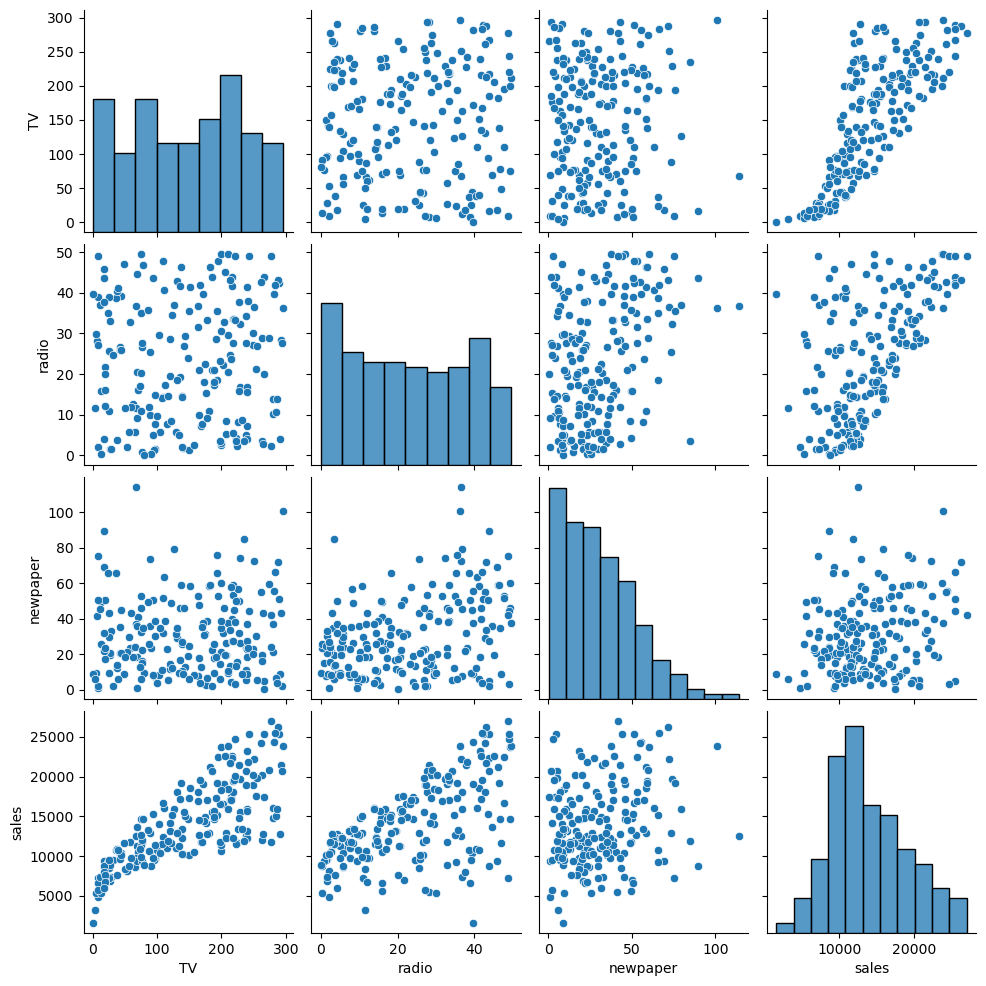

In [10]:
# Utiliza todas las celdas que necesites...
sns.pairplot(df);

c:\Users\julio\anaconda3\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)


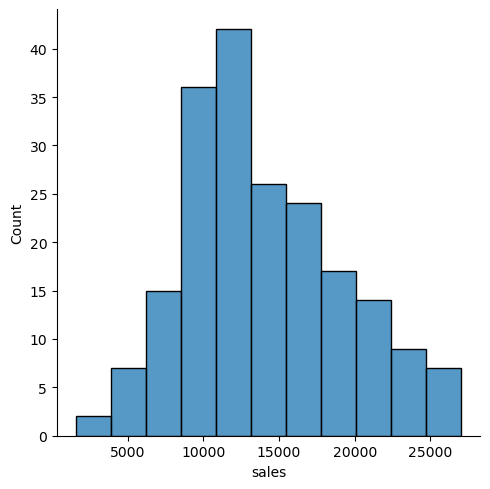

In [11]:
sns.displot(df['sales'])

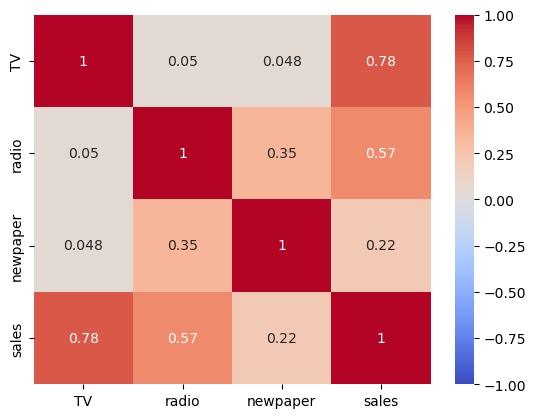

In [12]:
sns.heatmap(df.corr(), annot=True, vmin=-1, vmax=1, cmap='coolwarm');

## Modelado

In [13]:
# Manipulación datasets, entrenamiento, evaluación, nuevas iteraciones... Prueba modelos sin y con regularización.

In [14]:
df.columns

Index(['TV', 'radio', 'newpaper', 'sales'], dtype='object')

In [15]:
X = df.iloc[:,:-1]
y = df.iloc[:,-1]
y

1      10400.0
2       9300.0
3      18500.0
4      12900.0
5       7200.0
        ...   
195     7600.0
196     9700.0
197    12800.0
198    25500.0
199    13400.0
Name: sales, Length: 199, dtype: float64

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)

In [17]:
# Escalado de variables
from sklearn import preprocessing

std_scale = preprocessing.StandardScaler()
std_scale.fit(X_train)
X_train_scal = std_scale.transform(X_train)
X_test_scal = std_scale.transform(X_test)

In [18]:
from sklearn.metrics import mean_absolute_percentage_error

In [19]:
# Regresión lineal 

lm_scal = LinearRegression()
lm_scal.fit(X_train_scal, y_train)

y_pred_lm = lm_scal.predict(X_test_scal)
y_pred_tr_lm = lm_scal.predict(X_train_scal)

print('R2 test (regr lin):', lm_scal.score(X_test_scal, y_test))
print('R2 test (regr lin):', r2_score(y_test, y_pred_lm))
print('MAE test (regr lin):', mean_absolute_error(y_test, y_pred_lm))
print('MSE test (regr lin):', mean_squared_error(y_test, y_pred_lm))
print('RMSE test (regr lin):', np.sqrt(mean_squared_error(y_test, y_pred_lm)))
print('MAPE test (regr lin):', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_lm))
print()
print('R2 train (regr lin):', lm_scal.score(X_train_scal, y_train))
print('R2 train (regr lin):', r2_score(y_train, y_pred_tr_lm))
print('MAE train (regr lin):', mean_absolute_error(y_train, y_pred_tr_lm))
print('MSE train (regr lin):', mean_squared_error(y_train, y_pred_tr_lm))
print('RMSE train (regr lin):', np.sqrt(mean_squared_error(y_train, y_pred_tr_lm)))
print('MAPE train (regr lin):', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_tr_lm))

R2 test (regr lin): 0.8733836445096174
R2 test (regr lin): 0.8733836445096174
MAE test (regr lin): 1254.8294426951227
MSE test (regr lin): 2520107.8401506096
RMSE test (regr lin): 1587.48475273012
MAPE test (regr lin): 0.12085771842296263

R2 train (regr lin): 0.8987751617556998
R2 train (regr lin): 0.8987751617556998
MAE train (regr lin): 1274.0411732826617
MSE train (regr lin): 2872614.923945353
RMSE train (regr lin): 1694.8790292954104
MAPE train (regr lin): 0.14505339125691863


In [20]:
baseline_error = np.sqrt(mean_squared_error(y_test, y_pred_lm))

In [21]:
# Utiliza todas las celdas que necesites...

In [22]:
n_alphas = 100
alphas = np.logspace(-4, 3, n_alphas) 

In [23]:
# Regresión lineal con regularización Ridge 
coef_ridge = []
err_ridge = []
baseline = []

for a in alphas:
    lm_ridge = Ridge(alpha=a)
    lm_ridge.fit(X_train_scal, y_train)
    
    coef_ridge.append(lm_ridge.coef_)
    
    y_pred = lm_ridge.predict(X_test_scal)
    ridge_error = np.sqrt(mean_squared_error(y_pred, y_test))
    
    err_ridge.append(ridge_error)
    baseline.append(baseline_error)

In [24]:
min(err_ridge)

1513.5768373289295

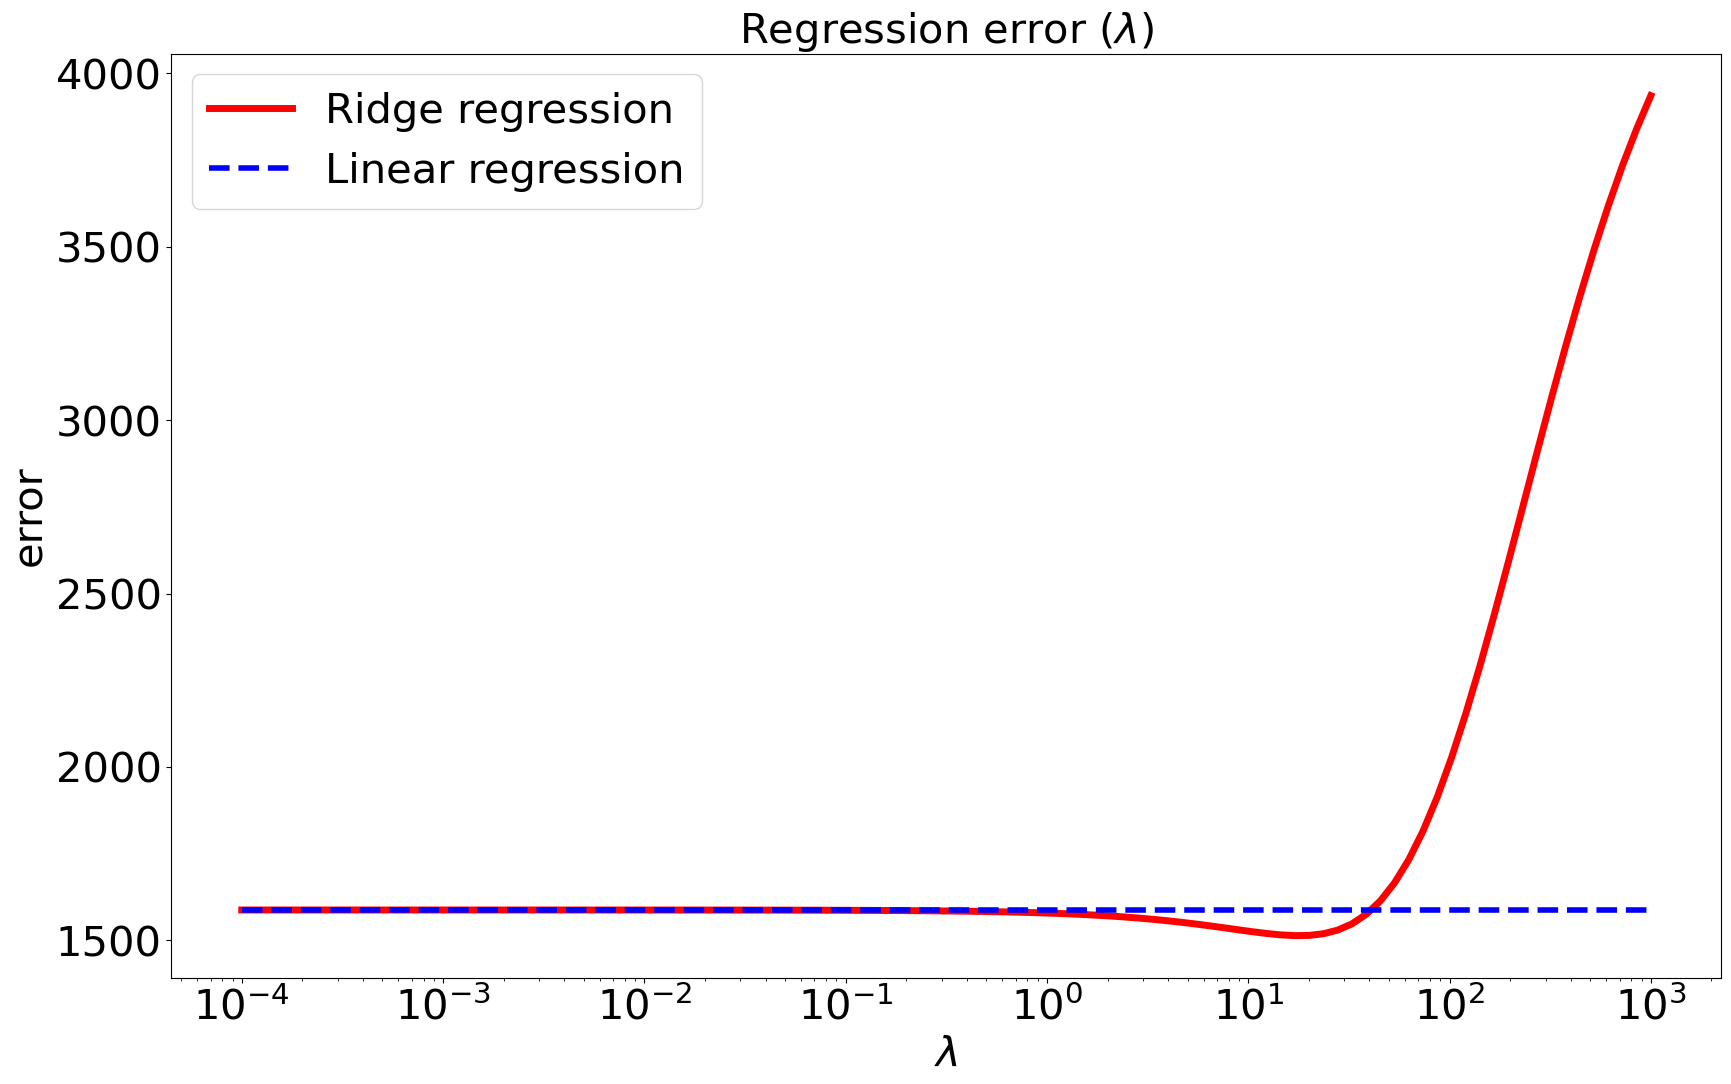

In [25]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_ridge, linewidth=5, color='red', label="Ridge regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [26]:
alfa_opt_ridge = alphas[np.where(err_ridge == np.min(err_ridge))[0]][0]
alfa_opt_ridge

17.073526474706888

In [27]:
lm_ridge_opt = Ridge(alpha=alfa_opt_ridge)
lm_ridge_opt.fit(X_train_scal, y_train)

y_pred_lm_ridge = lm_ridge_opt.predict(X_test_scal)
y_pred_tr_lm_ridge = lm_ridge_opt.predict(X_train_scal)

# print('R2 test (regr lin con reg Ridge):', lm_ridge_opt.score(X_test_scal, y_test))
print('R2 test (regr lin con reg Ridge):', r2_score(y_test, y_pred_lm_ridge))
print('MAE test (regr lin con reg Ridge):', mean_absolute_error(y_test, y_pred_lm_ridge))
print('MSE test (regr lin con reg Ridge):', mean_squared_error(y_test, y_pred_lm_ridge))
print('RMSE test (regr lin con reg Ridge):', np.sqrt(mean_squared_error(y_test, y_pred_lm_ridge)))
print('MAPE test (regr lin con reg Ridge):', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_lm_ridge))
print()
# print('R2 train (regr lin con reg Ridge):', lm_ridge_opt.score(X_train_scal, y_train))
print('R2 train (regr lin con reg Ridge):', r2_score(y_train, y_pred_tr_lm_ridge))
print('MAE train (regr lin con reg Ridge):', mean_absolute_error(y_train, y_pred_tr_lm_ridge))
print('MSE train (regr lin con reg Ridge):', mean_squared_error(y_train, y_pred_tr_lm_ridge))
print('RMSE train (regr lin con reg Ridge):', np.sqrt(mean_squared_error(y_train, y_pred_tr_lm_ridge)))
print('MAPE train (regr lin con reg Ridge):', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_tr_lm_ridge))


R2 test (regr lin con reg Ridge): 0.8848988589001544
MAE test (regr lin con reg Ridge): 1222.529621209968
MSE test (regr lin con reg Ridge): 2290914.8424986447
RMSE test (regr lin con reg Ridge): 1513.5768373289295
MAPE test (regr lin con reg Ridge): 0.11218717238603267

R2 train (regr lin con reg Ridge): 0.8906517066268024
MAE train (regr lin con reg Ridge): 1309.7097179494915
MSE train (regr lin con reg Ridge): 3103146.8649394424
RMSE train (regr lin con reg Ridge): 1761.5751090826193
MAPE train (regr lin con reg Ridge): 0.14367066640664117


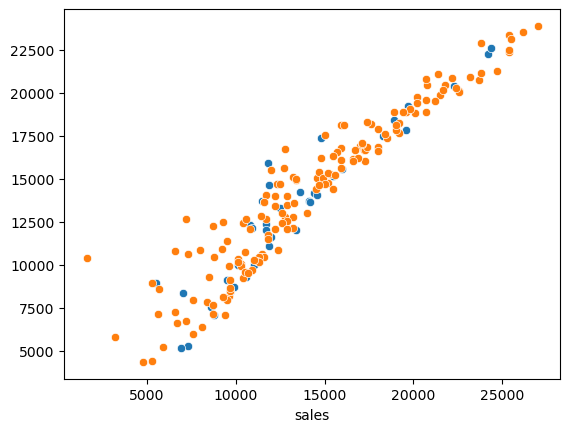

In [28]:
sns.scatterplot(x = y_test, y = y_pred_lm_ridge);
sns.scatterplot(x = y_train, y = y_pred_tr_lm_ridge);

In [29]:
# La regularización Ridge prácticamente no ha aportado mejora sobre la regresión lineal sin regularización. 

In [30]:
# Regresión lineal con regularización Lasso 
coef_lasso = []
err_lasso = []
# baseline = []

for a in alphas:
    lm_lasso = Lasso(alpha=a)
    lm_lasso.fit(X_train_scal, y_train)
    
    coef_ridge.append(lm_lasso.coef_)
    
    y_pred = lm_lasso.predict(X_test_scal)
    lasso_error = np.sqrt(mean_squared_error(y_pred, y_test))
    
    err_lasso.append(lasso_error)
    # baseline.append(baseline_error)

In [31]:
min(err_lasso)

1508.0136505062692

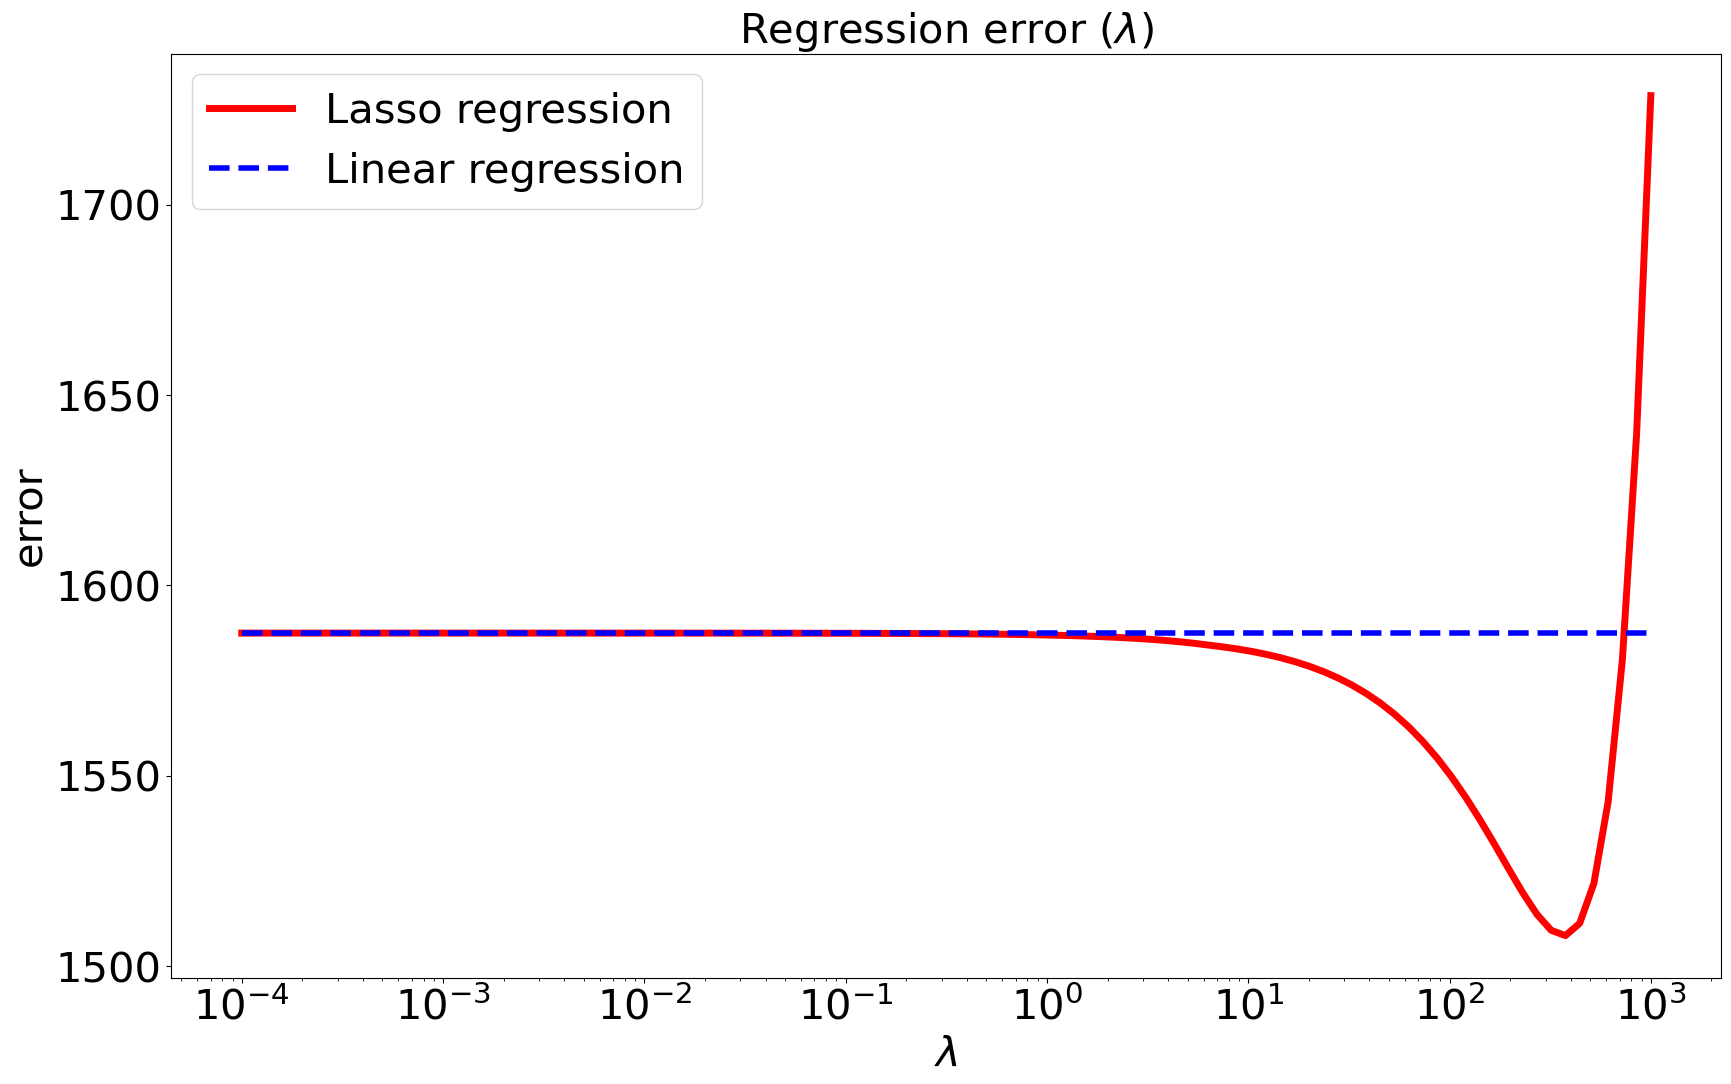

In [32]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_lasso, linewidth=5, color='red', label="Lasso regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [33]:
alfa_opt_lasso = alphas[np.where(err_lasso == np.min(err_lasso))[0]][0]
alfa_opt_lasso

376.49358067924635

In [34]:
lm_lasso_opt = Lasso(alpha=alfa_opt_lasso)
lm_lasso_opt.fit(X_train_scal, y_train)

y_pred_lm_lasso = lm_lasso_opt.predict(X_test_scal)
y_pred_tr_lm_lasso = lm_lasso_opt.predict(X_train_scal)

# print('R2 test (regr lin con reg Lasso):', lm_lasso_opt.score(X_test_scal, y_test))
print('R2 test (regr lin con reg Lasso):', r2_score(y_test, y_pred_lm_lasso))
print('MAE test (regr lin con reg Lasso):', mean_absolute_error(y_test, y_pred_lm_lasso))
print('MSE test (regr lin con reg Lasso):', mean_squared_error(y_test, y_pred_lm_lasso))
print('RMSE test (regr lin con reg Lasso):', np.sqrt(mean_squared_error(y_test, y_pred_lm_lasso)))
print('MAPE test (regr lin con reg Lasso):', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_lm_lasso))
print()
# print('R2 train (regr lin con reg Lasso):', lm_lasso_opt.score(X_train_scal, y_train))
print('R2 train (regr lin con reg Lasso):', r2_score(y_train, y_pred_tr_lm_lasso))
print('MAE train (regr lin con reg Lasso):', mean_absolute_error(y_train, y_pred_tr_lm_lasso))
print('MSE train (regr lin con reg Lasso):', mean_squared_error(y_train, y_pred_tr_lm_lasso))
print('RMSE train (regr lin con reg Lasso):', np.sqrt(mean_squared_error(y_train, y_pred_tr_lm_lasso)))
print('MAPE train (regr lin con reg Lasso):', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_tr_lm_lasso))

R2 test (regr lin con reg Lasso): 0.885743417779944
MAE test (regr lin con reg Lasso): 1192.3230690070054
MSE test (regr lin con reg Lasso): 2274105.170113244
RMSE test (regr lin con reg Lasso): 1508.0136505062692
MAPE test (regr lin con reg Lasso): 0.10816280714946136

R2 train (regr lin con reg Lasso): 0.8892272204174275
MAE train (regr lin con reg Lasso): 1320.251717196952
MSE train (regr lin con reg Lasso): 3143571.729182038
RMSE train (regr lin con reg Lasso): 1773.012049925786
MAPE train (regr lin con reg Lasso): 0.14270127258111107


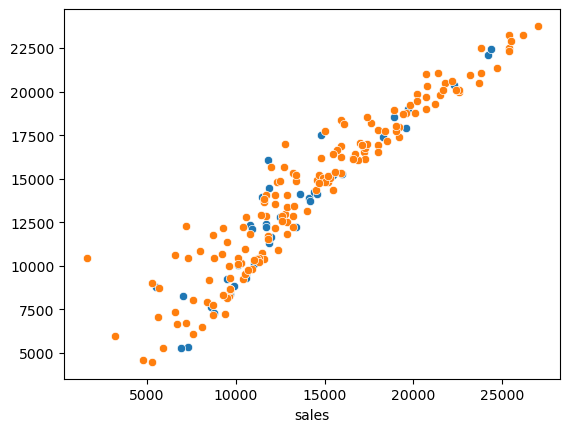

In [35]:
sns.scatterplot(x = y_test, y = y_pred_lm_lasso);
sns.scatterplot(x = y_train, y = y_pred_tr_lm_lasso);

In [36]:
# La regularización Lasso prácticamente no ha aportado mejora sobre la regresión lineal sin regularización. 

In [37]:
# Regresión lineal con regularización ElasticNet con l1_ratio = 0.5
from sklearn.linear_model import ElasticNet

coef_eln = []
err_eln = []
# baseline = []

for a in alphas:
    lm_eln = ElasticNet(alpha=a, l1_ratio = 0.5)
    lm_eln.fit(X_train_scal, y_train)
    
    coef_eln.append(lm_eln.coef_)
    
    y_pred = lm_eln.predict(X_test_scal)
    eln_error = np.sqrt(mean_squared_error(y_pred, y_test))
    
    err_eln.append(eln_error)
    # baseline.append(baseline_error)

In [38]:
min(err_eln)

1513.6944676966455

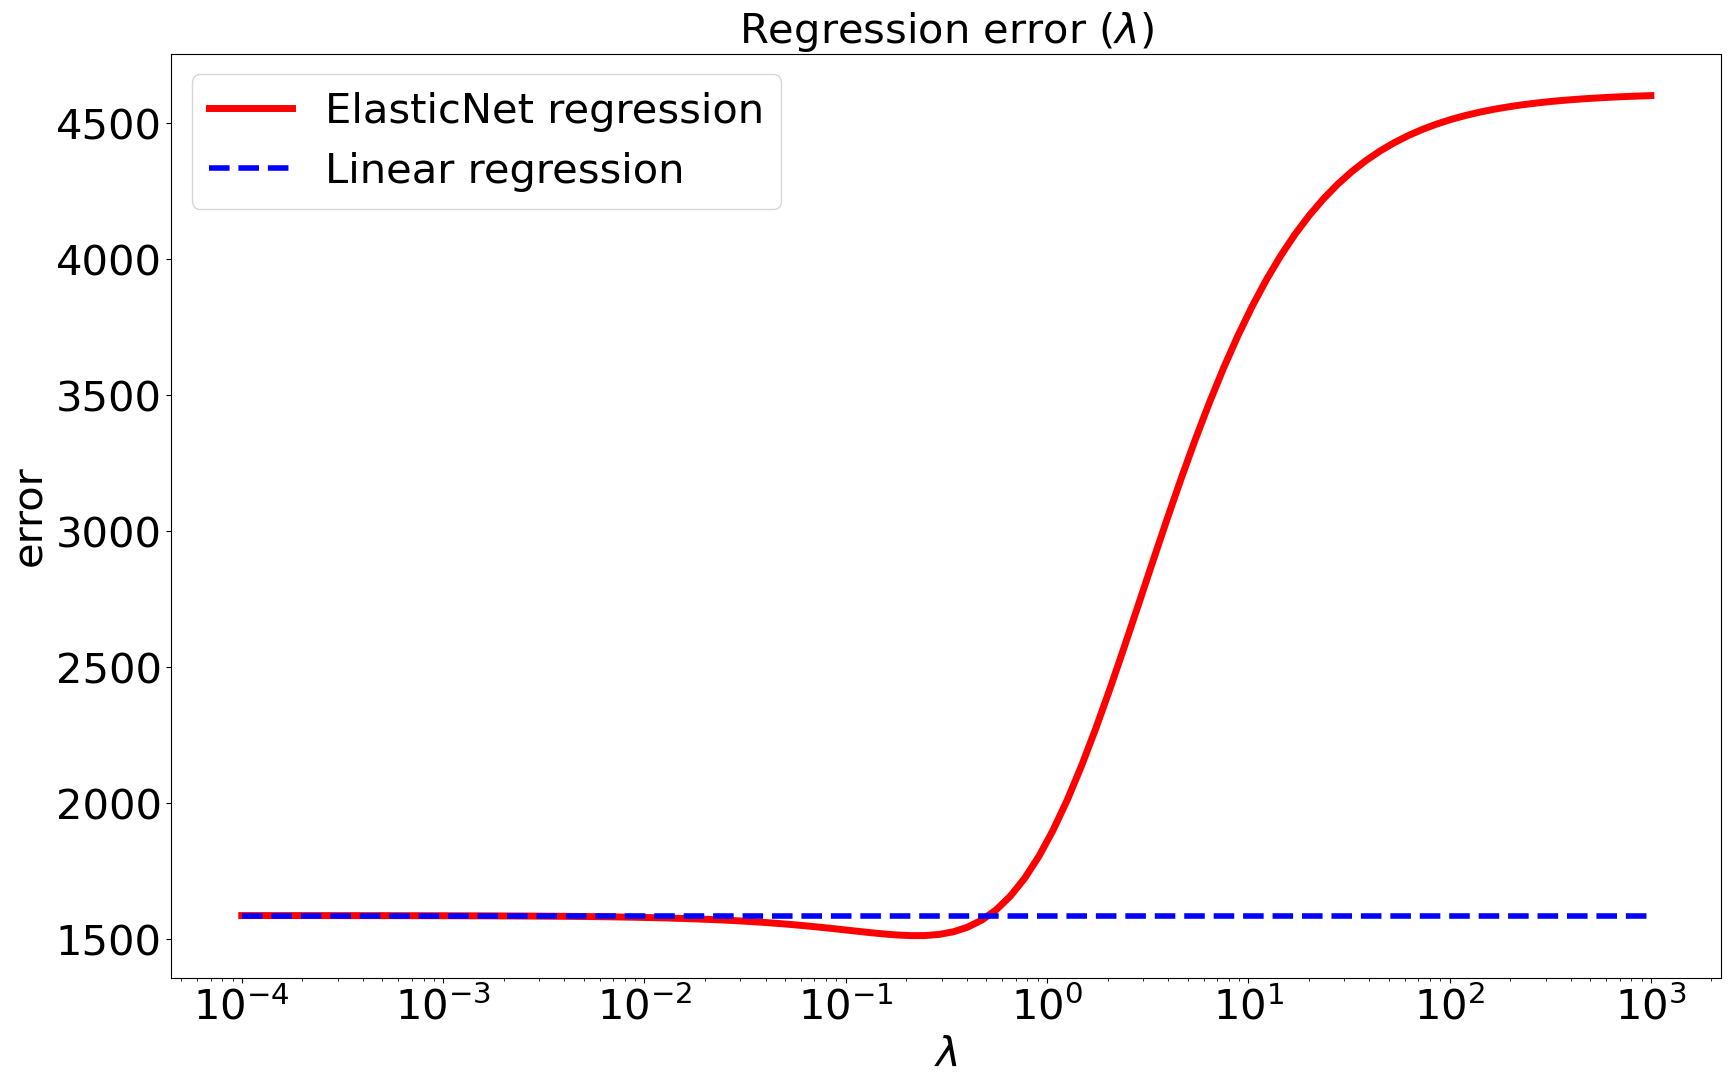

In [39]:
plt.figure(figsize=(20,12))
ax = plt.gca()
ax.plot(alphas, err_eln, linewidth=5, color='red', label="ElasticNet regression")
ax.plot(alphas, baseline, linewidth=4,linestyle='--', color='blue', label='Linear regression')
ax.set_xscale('log')
plt.xlabel(r'$\lambda$', fontsize=30)
plt.xticks(fontsize=30)
plt.yticks(fontsize=30)
plt.ylabel('error', fontsize=30)
ax.legend(fontsize=30)
plt.title(r'Regression error ($\lambda$)', fontsize=30)
plt.show()

In [40]:
alfa_opt_eln = alphas[np.where(err_eln == np.min(err_eln))[0]][0]
alfa_opt_eln

0.21049041445120198

In [41]:
lm_eln_opt = ElasticNet(alpha=alfa_opt_eln, l1_ratio = 0.5)
lm_eln_opt.fit(X_train_scal, y_train)

y_pred_lm_eln = lm_eln_opt.predict(X_test_scal)
y_pred_tr_lm_eln = lm_eln_opt.predict(X_train_scal)

# print('R2 test (regr lin con reg ElasticNet (l1_ratio=0.5)):', lm_eln_opt.score(X_test_scal, y_test))
print('R2 test (regr lin con reg ElasticNet (l1_ratio=0.5)):', r2_score(y_test, y_pred_lm_eln))
print('MAE test (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_absolute_error(y_test, y_pred_lm_eln))
print('MSE test (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_squared_error(y_test, y_pred_lm_eln))
print('RMSE test (regr lin con reg ElasticNet (l1_ratio=0.5)):', np.sqrt(mean_squared_error(y_test, y_pred_lm_eln)))
print('MAPE test (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_lm_eln))
print()
# print('R2 train (regr lin con reg ElasticNet (l1_ratio=0.5)):', lm_eln_opt.score(X_train_scal, y_train))
print('R2 train (regr lin con reg ElasticNet (l1_ratio=0.5)):', r2_score(y_train, y_pred_tr_lm_eln))
print('MAE train (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_absolute_error(y_train, y_pred_tr_lm_eln))
print('MSE train (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_squared_error(y_train, y_pred_tr_lm_eln))
print('RMSE train (regr lin con reg ElasticNet (l1_ratio=0.5)):', np.sqrt(mean_squared_error(y_train, y_pred_tr_lm_eln)))
print('MAPE train (regr lin con reg ElasticNet (l1_ratio=0.5)):', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_tr_lm_eln))

R2 test (regr lin con reg ElasticNet (l1_ratio=0.5)): 0.8848809676172842
MAE test (regr lin con reg ElasticNet (l1_ratio=0.5)): 1223.052834246241
MSE test (regr lin con reg ElasticNet (l1_ratio=0.5)): 2291270.941535431
RMSE test (regr lin con reg ElasticNet (l1_ratio=0.5)): 1513.6944676966455
MAPE test (regr lin con reg ElasticNet (l1_ratio=0.5)): 0.1123389530558132

R2 train (regr lin con reg ElasticNet (l1_ratio=0.5)): 0.8909358635937716
MAE train (regr lin con reg ElasticNet (l1_ratio=0.5)): 1308.5253677511548
MSE train (regr lin con reg ElasticNet (l1_ratio=0.5)): 3095082.9000251293
RMSE train (regr lin con reg ElasticNet (l1_ratio=0.5)): 1759.284769451816
MAPE train (regr lin con reg ElasticNet (l1_ratio=0.5)): 0.14365419944877045


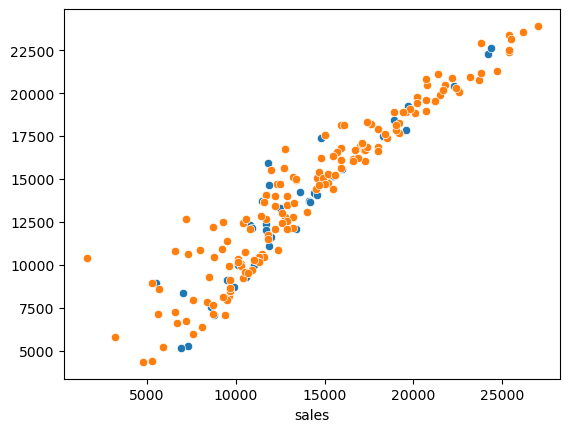

In [42]:
sns.scatterplot(x = y_test, y = y_pred_lm_eln);
sns.scatterplot(x = y_train, y = y_pred_tr_lm_eln);

In [43]:
# La regularización ElasticNet prácticamente no ha aportado mejora sobre la regresión lineal sin regularización. 

### Modelos Polinómicos

In [44]:
poly_feats = PolynomialFeatures(degree = 2)
# Para la regresión polinómica no importa, pero como regla general, se debería hacer el 
# fit solo a los datos de train, para evitar que se filtre información de los datos 
# de test. 
# poly_feats.fit(X)
poly_feats.fit(X_train_scal)
# X_poly2 = poly_feats.transform(X)
X_train2_scal = poly_feats.transform(X_train_scal)
X_test2_scal = poly_feats.transform(X_test_scal)
y_train2 = y_train
y_test2 = y_test
X_train2_scal

array([[ 1.00000000e+00,  1.19532063e+00, -1.63963762e-01, ...,
         2.68841151e-02,  4.45033154e-03,  7.36697142e-04],
       [ 1.00000000e+00,  8.96770666e-01,  9.31761263e-01, ...,
         8.68179051e-01,  6.32807507e-02,  4.61247412e-03],
       [ 1.00000000e+00,  1.30062313e+00, -1.35322629e+00, ...,
         1.83122139e+00,  7.12058638e-01,  2.76879413e-01],
       ...,
       [ 1.00000000e+00,  1.16176269e+00,  8.51586261e-01, ...,
         7.25199160e-01,  1.68896898e+00,  3.93356247e+00],
       [ 1.00000000e+00,  7.05510050e-02, -1.41335754e+00, ...,
         1.99757954e+00,  1.49605953e+00,  1.12045307e+00],
       [ 1.00000000e+00,  4.32745338e-01, -4.37895018e-01, ...,
         1.91752047e-01,  2.63717551e-01,  3.62692071e-01]])

In [45]:
poly_feats.get_feature_names_out()

array(['1', 'x0', 'x1', 'x2', 'x0^2', 'x0 x1', 'x0 x2', 'x1^2', 'x1 x2',
       'x2^2'], dtype=object)

In [46]:
qm_scal = LinearRegression()
qm_scal.fit(X_train2_scal, y_train2)

LinearRegression()

In [47]:
y_pred_train2 = qm_scal.predict(X_train2_scal)
y_pred_test2 = qm_scal.predict(X_test2_scal)

In [48]:
# print('R2 test (regr cuadrática):', qm_scal.score(X_test_scal, y_test))
print('R2 test (regr cuadrática):', r2_score(y_test, y_pred_test2))
print('MAE test (regr cuadrática):', mean_absolute_error(y_test, y_pred_test2))
print('MSE test (regr cuadrática):', mean_squared_error(y_test, y_pred_test2))
print('RMSE test (regr cuadrática):', np.sqrt(mean_squared_error(y_test, y_pred_test2)))
print('MAPE test (regr cuadrática):', mean_absolute_percentage_error(y_true=y_test, y_pred=y_pred_test2))
print()
# print('R2 train (regr cuadrática):', qm_scal.score(X_train_scal, y_train))
print('R2 train (regr cuadrática):', r2_score(y_train, y_pred_train2))
print('MAE train (regr cuadrática):', mean_absolute_error(y_train, y_pred_train2))
print('MSE train (regr cuadrática):', mean_squared_error(y_train, y_pred_train2))
print('RMSE train (regr cuadrática):', np.sqrt(mean_squared_error(y_train, y_pred_train2)))
print('MAPE train (regr cuadrática):', mean_absolute_percentage_error(y_true=y_train, y_pred=y_pred_train2))

R2 test (regr cuadrática): 0.9802864514378731
MAE test (regr cuadrática): 484.8588515142157
MSE test (regr cuadrática): 392368.4905966157
RMSE test (regr cuadrática): 626.3932395840617
MAPE test (regr cuadrática): 0.0455348109437345

R2 train (regr cuadrática): 0.98677981521615
MAE train (regr cuadrática): 428.68998389444914
MSE train (regr cuadrática): 375169.7781501893
RMSE train (regr cuadrática): 612.5110432883552
MAPE train (regr cuadrática): 0.05424994861051386


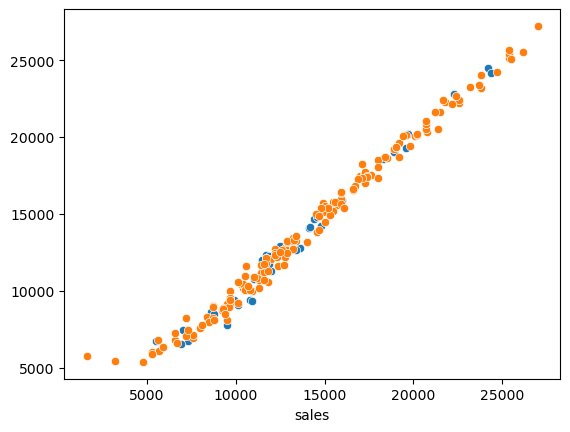

In [49]:
sns.scatterplot(x = y_test, y = y_pred_test2);
sns.scatterplot(x = y_train, y = y_pred_train2);

In [50]:
# La regresión cuadrática es claramente mejor que la regresión lineal con/sin regularización. 

## Resultados

In [51]:
# Interpreta, resume y destaca los puntos importantes de los resultados.

In [52]:
# Utiliza todas las celdas que necesites...

In [53]:
print('Ninguna de las regularizaciones ha aportado una mejora significativa a la regresión lineal.')
print('Es normal, ya que no había indicios de overfitting (las métricas de error y el R^2 eran parecidos en train y test).')
print('La regresión cuadrática es claramente mejor que la regresión lineal con/sin regularización.')

Ninguna de las regularizaciones ha aportado una mejora significativa a la regresión lineal.
Es normal, ya que no había indicios de overfitting (las métricas de error y el R^2 eran parecidos en train y test).
La regresión cuadrática es claramente mejor que la regresión lineal con/sin regularización.


Traduce a una fórmula tu mejor modelo (escribir la fórmula simplemente). 

In [59]:
medias = std_scale.mean_
escalas = std_scale.scale_
print(medias)
print(escalas)

[150.50314465  23.75408805  30.57106918]
[86.41769664 14.96725878 21.03992714]


In [60]:
poly_feats.get_feature_names_out()

array(['1', 'x0', 'x1', 'x2', 'x0^2', 'x0 x1', 'x0 x2', 'x1^2', 'x1 x2',
       'x2^2'], dtype=object)

In [61]:
X_train.columns

Index(['TV', 'radio', 'newpaper'], dtype='object')

In [62]:
coefs = qm_scal.coef_
coefs

array([ 0.00000000e+00,  3.80348744e+03,  2.89591004e+03,  1.19723107e+02,
       -8.31049369e+02,  1.47192101e+03, -1.45073301e+02,  7.36054014e-01,
        5.10573338e+01, -6.22633930e+00])

Fórmulas de la regresión cuadrática: 
<center>

$$
TV_{scl} = \frac{(TV-150.5)}{86.4}
$$

$$
radio_{scl} = \frac{(radio-23.8)}{15.0}
$$

$$
nwpp_{scl} = \frac{(nwpp-30.6)}{21.0}
$$

$$
Ventas = 3.80348744*10^3 \times TV_{scl} 
+ 2.89591004*10^3 \times radio_{scl} 
+ 1.19723107*10^2 \times nwpp_{scl} 
- 8.31049369*10^2 \times TV_{scl}^2 
+ 1.47192101*10^3 \times TV_{scl} \times radio_{scl} 
- 1.45073301*10^2 \times TV_{scl} \times nwpp_{scl} 
+ 7.36054014*10^{-1} \times radio_{scl}^2 
+ 5.10573338*10^1 \times radio_{scl} \times nwpp_{scl} 
- 6.22633930 \times nwpp_{scl}^2
$$

</center>